Dataset shape: (569, 30)
Variance retained by 10 PCs: 95.27%

     Case  Features  Accuracy  Train time (ms)
Original        30    0.9825            8.035
     PCA        10    0.9737            5.290
     LDA         1    0.9737            3.886


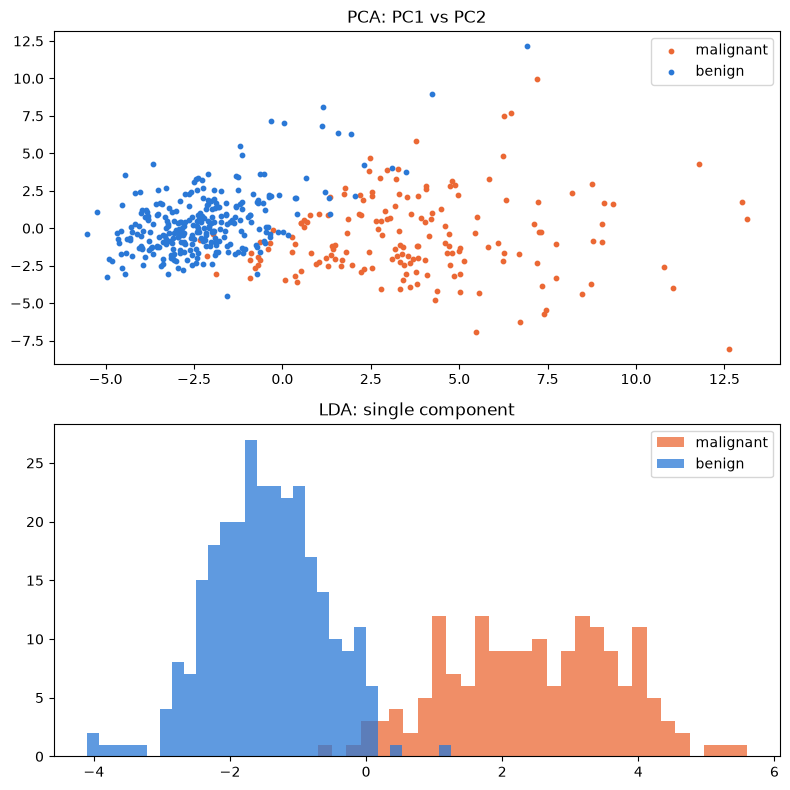

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
X, y = load_breast_cancer(return_X_y=True)
print("Dataset shape:", X.shape)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
sc = StandardScaler()
X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)
def evaluate(Xtr, Xte, name):
    t0 = time.perf_counter()
    for _ in range(50): # repeat 50 times for a stable timing
        clf = LogisticRegression(max_iter=5000).fit(Xtr, y_train)
    t = (time.perf_counter() - t0) / 50 * 1000
    acc = accuracy_score(y_test, clf.predict(Xte))
    return [name, Xtr.shape[1], round(acc, 4), round(t, 3)]
# Case 1: Original 30 features
r1 = evaluate(X_train, X_test, "Original")
# Case 2: PCA > 10 components
pca = PCA(n_components=10)
Xtr_p = pca.fit_transform(X_train); Xte_p = pca.transform(X_test)
print("Variance retained by 10 PCs: %.2f%%" % (pca.explained_variance_ratio_.sum() * 100))
r2 = evaluate(Xtr_p, Xte_p, "PCA")
# Case 3: LDA > 1 component (C - 1 = 1)
lda = LDA(n_components=1)
Xtr_l = lda.fit_transform(X_train, y_train); Xte_l = lda.transform(X_test)
r3 = evaluate(Xtr_l, Xte_l, "LDA")
res = pd.DataFrame([r1, r2, r3], columns=["Case", "Features", "Accuracy", "Train time (ms)"])
print("\n", res.to_string(index=False))
fig, ax = plt.subplots(2, 1, figsize=(8, 8))
for c, col, lab in [(0, "#eb6834", "malignant"), (1, "#2a78d6", "benign")]:
    ax[0].scatter(Xtr_p[y_train == c, 0], Xtr_p[y_train == c, 1], s=10, color=col, label=lab)
    ax[1].hist(Xtr_l[y_train == c, 0], bins=30, color=col, alpha=0.75, label=lab)
ax[0].set_title("PCA: PC1 vs PC2"); ax[1].set_title("LDA: single component")
ax[0].legend(); ax[1].legend(); plt.tight_layout()